In [4]:
import matplotlib.pyplot as plt

In [5]:
# Loss function: J(w) = w^2 / 2
def loss(w):
    return 0.5 * w**2

In [6]:
# Gradient of the loss: dJ/dw = w
def gradient(w):
    return w

In [7]:
learning_rate = 0.1
beta = 0.9
initial_weight = 10.0
epochs = 20

In [8]:
# Initialize Momentum
w_momentum = initial_weight
v_momentum = 0.0
momentum_weights = [w_momentum]

In [9]:
# Initialize NAG
w_nag = initial_weight
v_nag = 0.0
nag_weights = [w_nag]

In [10]:
for step in range(epochs):

    # 1. Ordinary Momentum
    grad_momentum = gradient(w_momentum)
    v_momentum = (beta * v_momentum + grad_momentum)
    w_momentum = (w_momentum - learning_rate * v_momentum)
    momentum_weights.append(w_momentum)

    # 2. Nesterov Accelerated Gradient
    lookahead_weight = (w_nag - learning_rate * beta * v_nag)
    grad_nag = gradient(lookahead_weight)
    v_nag = beta * v_nag + grad_nag
    w_nag = w_nag - learning_rate * v_nag

    nag_weights.append(w_nag)

In [12]:
# Print the results
print("Step | Momentum Weight | NAG Weight")
print("-" * 38)

for step in range(epochs + 1):
    print(
        f"{step:4} | "
        f"{momentum_weights[step]:15.5f} | "
        f"{nag_weights[step]:10.5f}"
    )

Step | Momentum Weight | NAG Weight
--------------------------------------
   0 |        10.00000 |   10.00000
   1 |         9.00000 |    9.00000
   2 |         7.20000 |    7.29000
   3 |         4.86000 |    5.17590
   4 |         2.26800 |    2.94589
   5 |        -0.29160 |    0.84499
   6 |        -2.56608 |   -0.94124
   7 |        -4.35650 |   -2.29395
   8 |        -5.53224 |   -3.16026
   9 |        -6.03717 |   -3.54595
  10 |        -5.88789 |   -3.50375
  11 |        -5.16476 |   -3.11920
  12 |        -3.99746 |   -2.49580
  13 |        -2.54714 |   -1.74126
  14 |        -0.98714 |   -0.95596
  15 |         0.51557 |   -0.22427
  16 |         1.81645 |    0.39083
  17 |         2.80560 |    0.84997
  18 |         3.41528 |    1.13688
  19 |         3.62246 |    1.25559
  20 |         3.44667 |    1.22619


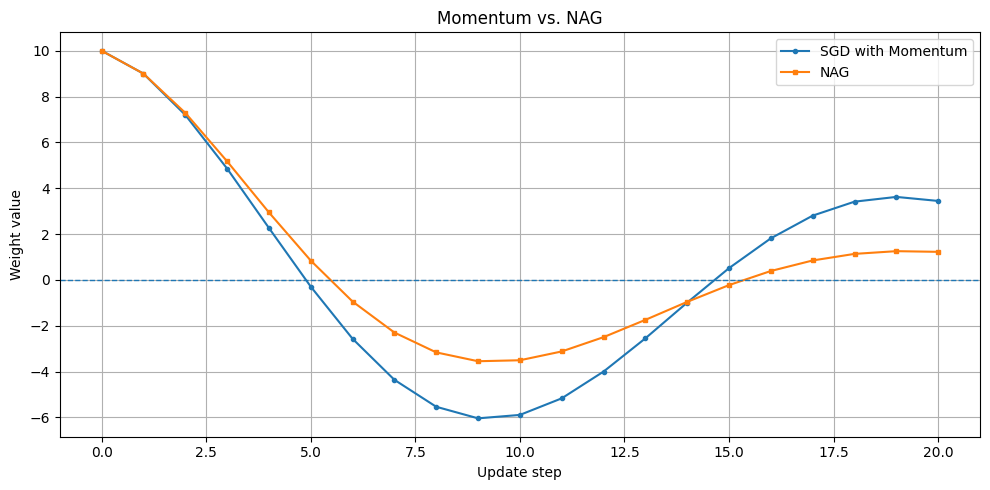

In [14]:
# Plot weight values over time
steps = range(epochs + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    steps, momentum_weights,
    marker="o", markersize=3,
    label="SGD with Momentum"
)

plt.plot(
    steps, nag_weights,
    marker="s", markersize=3,
    label="NAG"
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Update step")
plt.ylabel("Weight value")
plt.title("Momentum vs. NAG")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()